# PERCEPTRÓN MULTICAPA PARA "FASHION-MNIST"

# PREPARACIÓN

CARGAMOS LAS LIBRERÍAS

In [3]:
from tensorflow import keras
from keras.models import Sequential
from keras import datasets, layers, models
from keras.utils import plot_model
from keras.optimizers import Adam

2026-04-24 15:16:08.954008: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

##Cargamos los datos

In [ ]:
fashion = keras.datasets.fashion_mnist
(train_images,y_train),(test_images,y_test) = fashion.load_data()

# CODIFICAMOS LAS ETIQUETAS EN ESTILO "ONE-HOT"
num_classes = ___
train_labels = keras.utils.to_categorical(y_train, num_classes)
test_labels = keras.utils.to_categorical(y_test, num_classes)

#ESTANDARIZAMOS LAS IMÁGENES. Cada píxel tiene una tonalidad de gris que se representa desde 0 (blanco) a 255(negro)
train_images = ___
test_images = ___

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress','Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

Comprobamos la codificación de las etiquetas

In [ ]:
print(y_test[0])
print(train_labels[0])

9
[0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


Vemos el tamaño del conjunto de datos y la forma de las imágenes

In [ ]:
___
___

(60000, 28, 28)
(10000, 28, 28)


##Dibujamos unas imagen del conjunto de datos

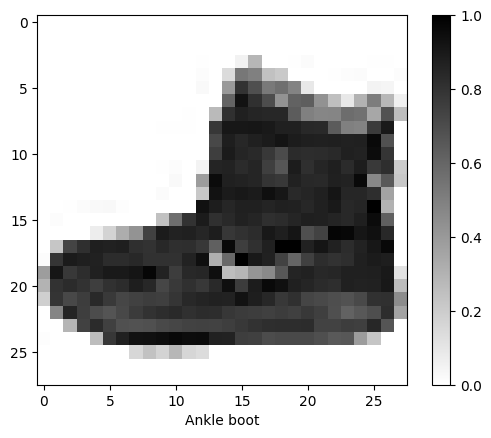

In [ ]:
plt.figure()
plt.imshow(train_images[0], cmap=plt.cm.binary)
plt.colorbar()
plt.grid(False)
plt.xlabel(class_names[y_train[0]])

plt.show()

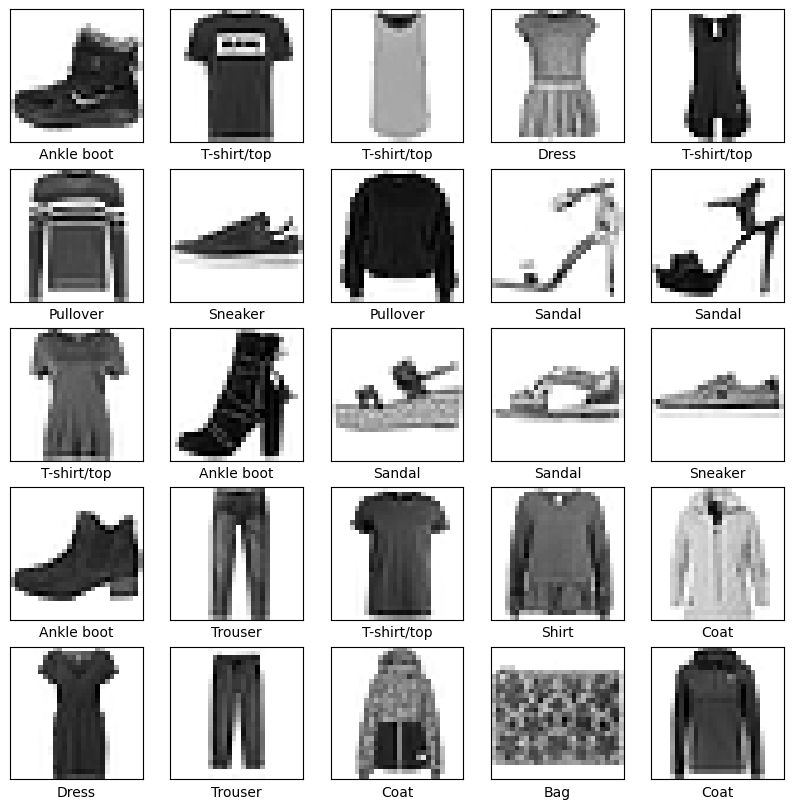

In [ ]:
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i], cmap=plt.cm.binary)
    plt.xlabel(class_names[y_train[i]])
plt.show()

#PERCEPTRÓN MULTICAPA

Cosntruimos un perceptrón multicapa con la librería KERAS

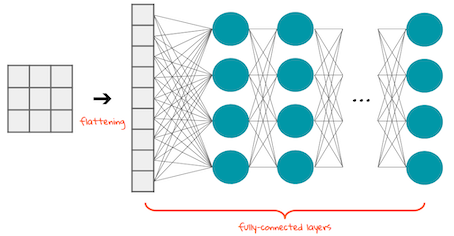

In [ ]:
def mlp_model():
  model =Sequential([
      layers.Input(shape=(___, ___)),
      layers.Flatten(),
      layers.Dense(units=64, activation='___'), # función de activación
      layers.Dense(units = ___, activation='___') # última capa de una red de clasificación
  ])
  return model

In [ ]:
model = mlp_model()
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 784)               0         
                                                                 
 dense (Dense)               (None, 64)                50240     
                                                                 
 dense_1 (Dense)             (None, 10)                650       
                                                                 
Total params: 50890 (198.79 KB)
Trainable params: 50890 (198.79 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


Se observa como las imágenes de 28*28 píxeles se han "aplanado" en un vector de dimensión 728.

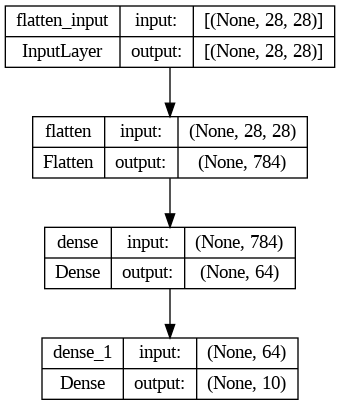

In [ ]:
plot_model(model,show_shapes=True)

## Pérdida: Error Cuadrático Medio
Primero usamos el Error Cuadrático Medio como función de pérdida

batch_size: num de ejemplos usados para calcular la función de pérdida

epochs: número de veces que la red "ve" todos los datos

In [ ]:
#CONFIGURACIÓN DE LOS HIPERPARÁMETROS
model = mlp_model()
batch_size = 128
epochs = 15
loss = "___"
optimizer = SGD(___=0.01)

#ENTRENAMOS LA RED
model.compile(loss=loss,
              optimizer=optimizer,
              metrics=["accuracy"])
history = model.fit(train_images, train_labels,
                    batch_size=batch_size,
                    epochs=epochs,
                    validation_data=(test_images, test_labels))

Epoch 1/15
469/469 [==============================] - 3s 4ms/step - loss: 0.0891 - accuracy: 0.1752 - val_loss: 0.0857 - val_accuracy: 0.2563
Epoch 2/15
469/469 [==============================] - 2s 3ms/step - loss: 0.0823 - accuracy: 0.3125 - val_loss: 0.0796 - val_accuracy: 0.3536
Epoch 3/15
469/469 [==============================] - 2s 3ms/step - loss: 0.0769 - accuracy: 0.3769 - val_loss: 0.0748 - val_accuracy: 0.4042
Epoch 4/15
469/469 [==============================] - 2s 5ms/step - loss: 0.0724 - accuracy: 0.4329 - val_loss: 0.0707 - val_accuracy: 0.4609
Epoch 5/15
469/469 [==============================] - 2s 3ms/step - loss: 0.0683 - accuracy: 0.5031 - val_loss: 0.0666 - val_accuracy: 0.5397
Epoch 6/15
469/469 [==============================] - 2s 3ms/step - loss: 0.0642 - accuracy: 0.5726 - val_loss: 0.0628 - val_accuracy: 0.5992
Epoch 7/15
469/469 [==============================] - 2s 3ms/step - loss: 0.0604 - accuracy: 0.6152 - val_loss: 0.0592 - val_accuracy: 0.6256
Epoch 

In [ ]:
test_loss, test_accuracy = model.evaluate(test_images,  test_labels, verbose=0)
print("La precisión es: ", np.round(test_accuracy,3))

La precisión es:  0.68


###Dibujamos la evolución del entrenamiento

In [ ]:
def plot_hist(history):
  plt.plot(history.history['accuracy'], label='accuracy')
  plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
  plt.xlabel('Epoch')
  plt.ylabel('Accuracy')
  plt.ylim([0.5, 1])
  plt.legend(loc='lower right')
  plt.show()



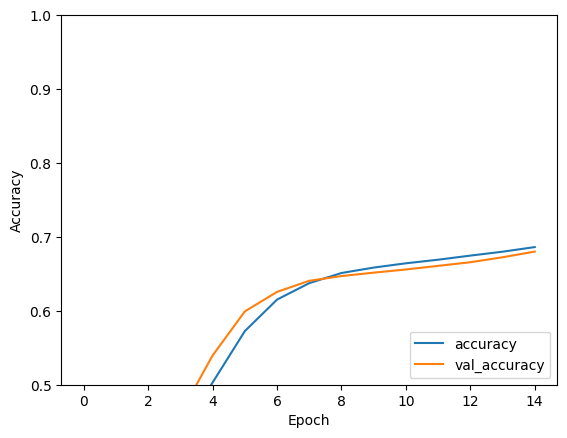

In [ ]:
plot_hist(history)

##Pérdida: Entropía Cruzada
Ahora cambiamos la función de pérdida a la entropía cruzada, que sabemos que es más adecuada para este problema de clasificación

In [ ]:
#CONFIGURACIÓN DE LOS HIPERPARÁMETROS
model = mlp_model()
batch_size = 128
epochs = 15
loss = "categorical_crossentropy"
optimizer = SGD(learning_rate=0.01)

#ENTRENAMOS LA RED
model.compile(loss=loss, optimizer=optimizer, metrics=["accuracy"])
history = model.fit(___, ___,
                    batch_size=batch_size, epochs=epochs,
                    validation_data=(___, ___))

Epoch 1/15
469/469 [==============================] - 2s 4ms/step - loss: 1.1632 - accuracy: 0.6367 - val_loss: 0.8216 - val_accuracy: 0.7293
Epoch 2/15
469/469 [==============================] - 2s 4ms/step - loss: 0.7176 - accuracy: 0.7665 - val_loss: 0.6782 - val_accuracy: 0.7716
Epoch 3/15
469/469 [==============================] - 2s 4ms/step - loss: 0.6215 - accuracy: 0.7969 - val_loss: 0.6184 - val_accuracy: 0.7905
Epoch 4/15
469/469 [==============================] - 2s 3ms/step - loss: 0.5710 - accuracy: 0.8102 - val_loss: 0.5808 - val_accuracy: 0.8039
Epoch 5/15
469/469 [==============================] - 2s 3ms/step - loss: 0.5392 - accuracy: 0.8209 - val_loss: 0.5540 - val_accuracy: 0.8117
Epoch 6/15
469/469 [==============================] - 2s 3ms/step - loss: 0.5169 - accuracy: 0.8270 - val_loss: 0.5339 - val_accuracy: 0.8193
Epoch 7/15
469/469 [==============================] - 2s 4ms/step - loss: 0.4998 - accuracy: 0.8325 - val_loss: 0.5214 - val_accuracy: 0.8233
Epoch 

In [ ]:
test_loss, test_accuracy = model.evaluate(___,  ___, verbose=0)
print("La precisión es: ", np.round(test_accuracy,3))

La precisión es:  0.837


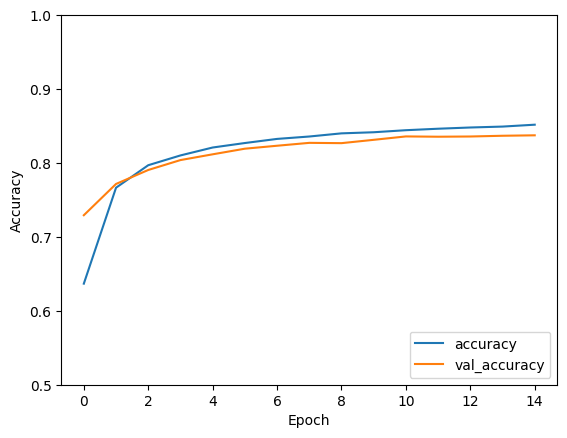

In [ ]:
plot_hist(history)

###Mostramos los resultados

In [ ]:
predictions = model.___(test_images)

313/313 [==============================] - 1s 2ms/step


In [ ]:
def plot_image(i, predictions_array, true_label, img):
  predictions_array, true_label, img = predictions_array, true_label[i], img[i]
  plt.grid(False)
  plt.xticks([])
  plt.yticks([])

  plt.imshow(img, cmap=plt.cm.binary)

  predicted_label = np.argmax(predictions_array)
  if predicted_label == true_label:
    color = 'blue'
  else:
    color = 'red'

  plt.xlabel("{} {:2.0f}% ({})".format(class_names[predicted_label],
                                100*np.max(predictions_array),
                                class_names[true_label]),
                                color=color)

def plot_value_array(i, predictions_array, true_label):
  predictions_array, true_label = predictions_array, true_label[i]
  plt.grid(False)
  plt.xticks(range(10))
  plt.yticks([])
  thisplot = plt.bar(range(10), predictions_array, color="#777777")
  plt.ylim([0, 1])
  predicted_label = np.argmax(predictions_array)

  thisplot[predicted_label].set_color('red')
  thisplot[true_label].set_color('blue')

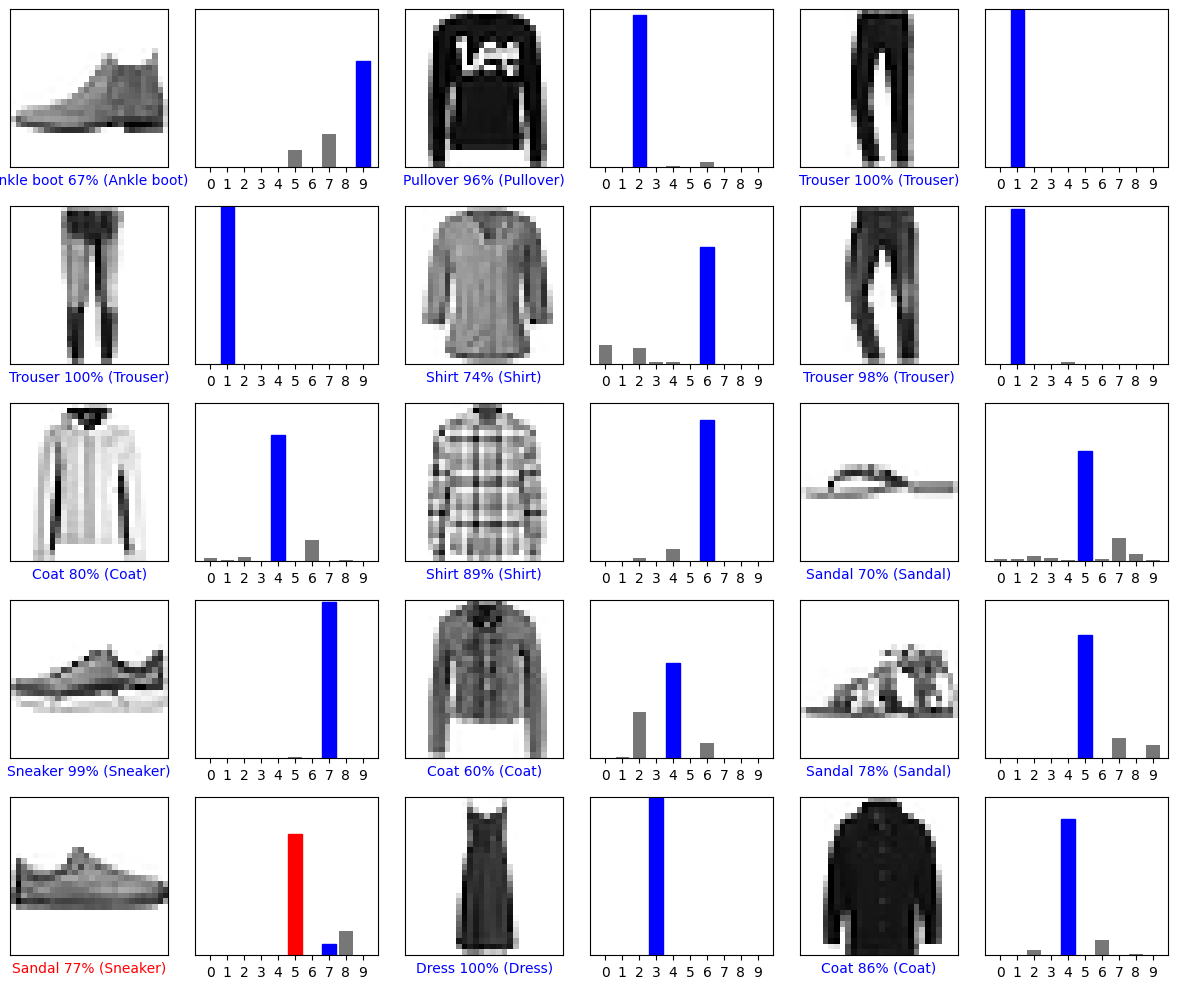

In [ ]:
#Muestra las imágenes, la predicción y la salida completa de la última capa

num_rows = 5
num_cols = 3
num_images = num_rows*num_cols
plt.figure(figsize=(2*2*num_cols, 2*num_rows))
for i in range(num_images):
  plt.subplot(num_rows, 2*num_cols, 2*i+1)
  plot_image(i, predictions[i], y_test, test_images)
  plt.subplot(num_rows, 2*num_cols, 2*i+2)
  plot_value_array(i, predictions[i], y_test)
plt.tight_layout()
plt.show()